# Part 1 — Bioinformatics: from BAM files to dashboard inputs

This notebook turns aligned reads (`.bam`) into the three kinds of files the dashboard reads:

| Dashboard module | File(s) | Produced by |
|---|---|---|
| Genome quality (sequencing depth) | `<virus>_avg.json`, `<virus>_indiv.json` | `data_curation/Extract-pileup` |
| Phylogenetic tree | `<Tree-name>.json` (Auspice) | `data_curation/Nextstrain-pipelines` |
| Time series, map, co-infections | `metadata_sequencing.tsv`, `metadata_pcr.tsv`, `metadata_co_infection_sequencing.tsv` | `data_curation/Nextstrain-pipelines` + one pandas step |

```
BAM ──► Extract-pileup ──► depth files ──► pileup JSONs ─────────────────────────┐
                      └──► consensus FASTA ─┐                                    ├──► dashboard/static/
             sample metadata ───────────────┴─► Nextstrain pipeline ──► trees + metadata ┘
```

**Toy dataset.** We simulate a small, fully synthetic run: 3 viruses — RSV (subtypes A and B), Influenza A (H3N2, segmented) and human parainfluenza virus 3 (HPIV-3, a virus without an official Nextclade dataset) — 19 samples plus one RSV-A + HPIV-3 co-infection. Each choice exercises a different code path: substrains, segments and custom phylogeny datasets.

Run the cells top to bottom (in the `revseq-tutorial` environment, see `tutorial/README.md`). Every step writes into `tutorial/workdir/`, which you can delete at any time to start over. Cells marked **Your data** show what to change for your own project.

> **Reading this on the website?** The cells are read-only here. To run them, open the repository in Codespaces (free with a GitHub account, nothing to install) or set up your computer as described on the [start page](README.md).
>
> [![Open in GitHub Codespaces](https://github.com/codespaces/badge.svg)](https://codespaces.new/charlynebuerki/ReVSeq-dashboard?quickstart=1)

## 0. Setup

In [1]:
import os, shutil, subprocess
from pathlib import Path
import pandas as pd

# Run everything from the repository root, whether the notebook was opened from tutorial/ or the root.
if Path.cwd().name == "tutorial":
    os.chdir("..")
REPO = Path.cwd()
WORK = REPO / "tutorial/workdir"
WORK.mkdir(parents=True, exist_ok=True)
EXTRACT = REPO / "data_curation/Extract-pileup"
NEXTSTRAIN = REPO / "data_curation/Nextstrain-pipelines"
print("Repository:", REPO.name)

Repository: tutorial


In [2]:
%%bash
# All command-line tools come from tutorial/environment.yml.
for tool in minimap2 samtools bcftools snakemake nextclade; do
  printf "%-10s %s\n" "$tool" "$($tool --version 2>&1 | head -1)"
done

minimap2   2.28-r1209


samtools   samtools 1.21


bcftools   bcftools 1.21


snakemake  7.32.4


nextclade  nextclade 3.18.0


## 1. Input data

### 1.1 Simulate a toy run
`tutorial/scripts/make_toy_data.py` mutates public reference genomes from the repository's reference library, simulates paired-end reads with uneven coverage (some samples have a poorly covered region, and three RSV-A samples have no coverage at all over part of the G gene, as a failed amplicon would leave; Part 2 shows how to spot it) and maps them with `minimap2`. It is seeded, so every run produces the same files.

> **Your data:** skip this step — you already have one BAM per sample and virus, plus the reference FASTA each BAM was aligned to.

In [3]:
%%time
!python tutorial/scripts/make_toy_data.py --outdir tutorial/workdir/toy_data --threads 4 | grep -v "bam$"
TOY = WORK / "toy_data"

[toy] rsv-a samples without coverage at 4900-5250: TOY004, TOY007, TOY015
[toy] 21 BAMs, manifest and sample sheet written to tutorial/workdir/toy_data


CPU times: user 86.1 ms, sys: 44.3 ms, total: 130 ms
Wall time: 16.8 s


### 1.2 The two input tables
**BAM manifest** — one row per BAM, read by `batch_pipeline.py`. The four columns are required:

In [4]:
manifest = pd.read_csv(TOY / "manifest.tsv", sep="\t")
manifest.assign(bam_path=manifest.bam_path.map(lambda p: Path(p).name),
                reference_path=manifest.reference_path.map(lambda p: Path(p).name)).head()

,sample_id,taxon_id,bam_path,reference_path
0,TOY001,208895,TOY001_rsv-b.bam,rsv-b.fasta
1,TOY002,11216,TOY002_hpiv-3.bam,hpiv-3.fasta
2,TOY003,41857,TOY003_flu-a-h3n2.bam,flu-a-h3n2.fasta
3,TOY004,208893,TOY004_rsv-a.bam,rsv-a.fasta
4,TOY005,41857,TOY005_flu-a-h3n2.bam,flu-a-h3n2.fasta


**Sample sheet** — one row per sample and detected virus. `virus` is the key used by the Nextstrain pipeline (one folder per virus); `virus_identified` / `Virus_PCR` are the sequencing and PCR results as your lab reports them (free text, harmonized later). Locations are written inconsistently on purpose (`ZH`, `Zürich`, …): the dashboard maps them to region codes.

In [5]:
samples = pd.read_csv(TOY / "samples.tsv", sep="\t", keep_default_na=False)
samples

,SampleID,virus,date,location,virus_identified,Virus_PCR
0,TOY001,rsv-b,2024-10-07,Zürich,rsv b,RSV - A/B
1,TOY002,hpiv-3,2024-10-18,BE,parainfluenza 3,Parainfluenza 3
2,TOY003,flu-a-h3n2,2024-10-23,ZH,influenza a h3n2,Influenza A
3,TOY004,rsv-a,2024-10-28,Luzern,rsv a,RSV - A/B
4,TOY005,flu-a-h3n2,2024-11-01,ZH,influenza a h3n2,Influenza A
5,TOY006,hpiv-3,2024-11-06,TI,parainfluenza 3,Parainfluenza 3
6,TOY007,rsv-a,2024-11-20,TI,rsv a,RSV - A/B
7,TOY008,hpiv-3,2024-11-30,Zürich,parainfluenza 3,Parainfluenza 3
8,TOY009,flu-a-h3n2,2024-12-05,Basel-Stadt,influenza a h3n2,Influenza A
9,TOY010,rsv-b,2025-01-10,Basel-Stadt,rsv b,RSV - A/B


## 2. Depth pileups and consensus genomes (`Extract-pileup`)
For every manifest row, `batch_pipeline.py` runs `samtools depth` (per-base depth), masks positions below `--min-depth`, and calls a consensus with `bcftools` (`mpileup → call → consensus`).

In [6]:
%%time
!python data_curation/Extract-pileup/batch_pipeline.py \
    --bam-manifest tutorial/workdir/toy_data/manifest.tsv \
    --outdir tutorial/workdir/extract \
    --min-depth 10 --jobs 4 --no-resume 2>&1 | tail -1

[batch] All BAM manifest targets completed.


CPU times: user 15 ms, sys: 9.27 ms, total: 24.3 ms
Wall time: 1.88 s


Each sample gets a depth file, a low-depth mask and a consensus FASTA:

In [7]:
!ls tutorial/workdir/extract/TOY001
!head -3 tutorial/workdir/extract/TOY001/pileup_TOY001_*.txt

calls_TOY001_208895.vcf.gz     mask_TOY001_208895.bed
calls_TOY001_208895.vcf.gz.csi pileup_TOY001_208895.txt
consensus_TOY001_208895.fasta


EPI_ISL_1653999	1	138
EPI_ISL_1653999	2	138
EPI_ISL_1653999	3	138


## 3. Pileup JSONs for the genome-quality module
The two builder scripts read **one folder per virus** containing that virus' depth files, and write:
- `<virus>_avg.json`: per-position median and inter-quartile range across samples (default dashboard view);
- `<virus>_indiv.json`: one depth trace per sample (individual view).

The sample name shown in the dashboard is taken from the file name, so we copy the depth files as `<sample>_depth.txt`. The manifest identifies each reference by its taxon ID; `VIRUS_BY_TAXON` names the virus folder for each one. Segmented viruses are recognised through `defaults/flu_segments_ref.csv`, which maps each reference record (e.g. `CY163680.1`) to a segment (`HA`).

In [8]:
# Your data: one entry per reference taxon ID in your manifest.
VIRUS_BY_TAXON = {208893: "rsv-a", 208895: "rsv-b", 41857: "flu-a-h3n2", 11216: "hpiv-3"}

PILEUPS = WORK / "pileups"
shutil.rmtree(PILEUPS, ignore_errors=True)
runs = manifest.assign(SampleID=manifest.sample_id, virus=manifest.taxon_id.map(VIRUS_BY_TAXON))
for row in runs.itertuples():
    target = PILEUPS / row.virus / f"{row.sample_id}_depth.txt"
    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(WORK / "extract" / row.sample_id / f"pileup_{row.sample_id}_{row.taxon_id}.txt", target)
{virus: len(list((PILEUPS / virus).iterdir())) for virus in sorted(os.listdir(PILEUPS))}

{'flu-a-h3n2': 5, 'hpiv-3': 5, 'rsv-a': 7, 'rsv-b': 4}

In [9]:
%%bash
for virus in rsv-a rsv-b flu-a-h3n2 hpiv-3; do
  for builder in build_pileup_avg_json.py build_pileup_individual_json.py; do
    python data_curation/Extract-pileup/$builder "$virus" \
      --input-root tutorial/workdir/pileups \
      --segment-ref-table data_curation/Extract-pileup/defaults/flu_segments_ref.csv
  done
done

Wrote: tutorial/workdir/pileups/rsv-a/rsv-a_avg.json


Wrote: tutorial/workdir/pileups/rsv-a/rsv-a_indiv.json


Wrote: tutorial/workdir/pileups/rsv-b/rsv-b_avg.json


Wrote: tutorial/workdir/pileups/rsv-b/rsv-b_indiv.json


Wrote: tutorial/workdir/pileups/flu-a-h3n2/flu-a-h3n2_avg.json


Wrote: tutorial/workdir/pileups/flu-a-h3n2/flu-a-h3n2_indiv.json


Wrote: tutorial/workdir/pileups/hpiv-3/hpiv-3_avg.json


Wrote: tutorial/workdir/pileups/hpiv-3/hpiv-3_indiv.json


A quick look at what the dashboard will show for RSV-A. The dip around 4.9–5.3 kb is where three samples have no reads; we come back to it in Part 2:

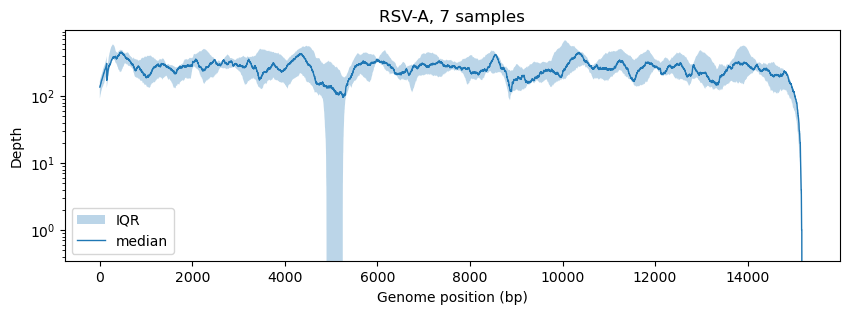

In [10]:
import json
import matplotlib.pyplot as plt

avg = json.loads((PILEUPS / "rsv-a/rsv-a_avg.json").read_text())
fig, ax = plt.subplots(figsize=(10, 3))
ax.fill_between(avg["positions"], avg["q1"], avg["q3"], alpha=0.3, label="IQR")
ax.plot(avg["positions"], avg["median"], lw=1, label="median")
ax.set(yscale="log", xlabel="Genome position (bp)", ylabel="Depth", title=f"RSV-A, {avg['n_files']} samples")
ax.legend();

## 4. Phylogenies and metadata (`Nextstrain-pipelines`)
The Snakemake pipeline needs, per virus, a folder `data/local_data/<virus>/` with
- `sequences.fasta`: the consensus genomes, and
- `metadata.tsv`: at least `SampleID`, `date`, `location`, `virus_identified` and (optional) `Virus_PCR`.

It places the sequences on a Nextclade reference tree and writes the dashboard metadata. We run it in its own working directory (`tutorial/workdir/nextstrain`) so the repository stays untouched.

### 4.1 Consensus genomes and metadata per virus
Sequence names follow the dashboard convention `SampleID|date|location`. For influenza the tree is built on the HA segment only, so we keep that record.

In [11]:
NS_WORK = WORK / "nextstrain"
HA_RECORD = "CY163680.1"  # HA segment of the H3N2 reference

def read_fasta(path):
    records, name = {}, None
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            name = line[1:]
            records[name] = []
        else:
            records[name].append(line.strip())
    return {name: "".join(seq) for name, seq in records.items()}

for virus, rows in runs.merge(samples, on=["SampleID", "virus"]).groupby("virus"):
    folder = NS_WORK / "data/local_data" / virus
    folder.mkdir(parents=True, exist_ok=True)
    with open(folder / "sequences.fasta", "w") as out:
        for row in rows.itertuples():
            consensus = read_fasta(WORK / "extract" / row.SampleID / f"consensus_{row.SampleID}_{row.taxon_id}.fasta")
            seq = consensus.get(f"{row.taxon_id}|{HA_RECORD}") or next(iter(consensus.values()))
            out.write(f">{row.SampleID}|{row.date}|{row.location}\n{seq}\n")
    rows[["SampleID", "date", "location", "virus_identified", "Virus_PCR"]].to_csv(folder / "metadata.tsv", sep="\t", index=False)
sorted(p.relative_to(NS_WORK).as_posix() for p in NS_WORK.glob("data/local_data/*/*"))

['data/local_data/flu-a-h3n2/metadata.tsv',
 'data/local_data/flu-a-h3n2/sequences.fasta',
 'data/local_data/hpiv-3/metadata.tsv',
 'data/local_data/hpiv-3/sequences.fasta',
 'data/local_data/rsv-a/metadata.tsv',
 'data/local_data/rsv-a/sequences.fasta',
 'data/local_data/rsv-b/metadata.tsv',
 'data/local_data/rsv-b/sequences.fasta']

### 4.2 Pipeline configuration
`viruses` lists the folders to process. `nextclade_datasets` says where each reference tree comes from:
- a **Nextclade dataset name** (`nextstrain/...`, see `nextclade dataset list`) is downloaded automatically;
- a **path to a zip** is used for viruses without an official dataset. The HPIV-3 zip shipped in `tutorial/data/` was built from public GenBank sequences with the `ingest/` pipeline (see `data_curation/Nextstrain-pipelines/ingest/README.md`).

`nice_virus_names` sets the tree file names, which the dashboard configuration refers to in Part 2.

In [12]:
%%writefile tutorial/workdir/nextstrain/configfile.yaml
viruses:
  - rsv-a
  - rsv-b
  - flu-a-h3n2
  - hpiv-3

nextclade_datasets:
  rsv-a: nextstrain/rsv/a/EPI_ISL_412866
  rsv-b: nextstrain/rsv/b/EPI_ISL_1653999
  flu-a-h3n2: nextstrain/flu/h3n2/ha/EPI1857216
  hpiv-3: ../../data/nextclade_dataset_hpiv-3.zip   # relative to tutorial/workdir/nextstrain

nice_virus_names:
  rsv-a: RSV-A
  rsv-b: RSV-B
  flu-a-h3n2: Influenza-A-H3N2-HA
  hpiv-3: HPIV-3

Overwriting tutorial/workdir/nextstrain/configfile.yaml


### 4.3 Run the pipeline
`-s` points to the pipeline, `-d` to our working directory (where `configfile.yaml` and `data/` live).

In [13]:
%%time
!snakemake -s data_curation/Nextstrain-pipelines/Snakefile -d tutorial/workdir/nextstrain --cores 4 --quiet rules 2>&1 | tail -3

Select jobs to execute...
Select jobs to execute...
Complete log: .snakemake/log/2026-10-28T164446.998172.snakemake.log


CPU times: user 8.89 ms, sys: 8.2 ms, total: 17.1 ms
Wall time: 1.64 s


Nextclade also reports clades and quality control for every sequence. (The toy influenza genomes derive from a 2005 reference, older than the dataset's clade system, hence `unassigned`; custom datasets such as HPIV-3 carry no clade nomenclature.)

In [14]:
qc = pd.concat(
    pd.read_csv(path, sep="\t").assign(virus=path.parent.name)
    for path in sorted((NS_WORK / "results/nextclade").glob("*/metadata.tsv"))
)
qc[["virus", "seqName", "clade", "qc.overallStatus", "coverage"]]

,virus,seqName,clade,qc.overallStatus,coverage
0,flu-a-h3n2,TOY009|2024-12-05|Basel-Stadt,unassigned,good,0.441211
1,flu-a-h3n2,TOY005|2024-11-01|ZH,unassigned,good,0.949942
2,flu-a-h3n2,TOY003|2024-10-23|ZH,unassigned,mediocre,0.944703
3,flu-a-h3n2,TOY013|2025-01-12|BE,unassigned,good,0.929569
4,flu-a-h3n2,TOY014|2025-01-17|VD,unassigned,mediocre,0.962165
0,hpiv-3,TOY012|2025-01-11|Basel-Stadt,dummy,good,0.999741
1,hpiv-3,TOY006|2024-11-06|TI,dummy,good,0.958414
2,hpiv-3,TOY020|2025-01-20|Kanton Bern,dummy,good,0.997736
3,hpiv-3,TOY008|2024-11-30|Zürich,dummy,good,0.998318
4,hpiv-3,TOY002|2024-10-18|BE,dummy,good,0.999159


And the harmonized metadata the dashboard reads (`Match_PCR` compares the sequencing and PCR results):

In [15]:
pd.read_csv(NS_WORK / "results/dashboard-metadata/metadata_sequencing.tsv", sep="\t").head()

,strain,virus_identified,date,location,Match_PCR
0,TOY004|2024-10-28|Luzern,rsv a,2024-10-28,Luzern,True
1,TOY007|2024-11-20|TI,rsv a,2024-11-20,TI,True
2,TOY015|2025-02-06|Genève,rsv a,2025-02-06,Genève,True
3,TOY016|2025-02-19|TI,rsv a,2025-02-19,TI,True
4,TOY017|2025-02-26|ZH,rsv a,2025-02-26,ZH,True


## 5. Hand the results over to the dashboard
The dashboard reads everything from `dashboard/static/` (these folders are git-ignored):

| Destination | Content |
|---|---|
| `dashboard/static/data/` | `metadata_sequencing.tsv`, `metadata_pcr.tsv`, `metadata_co_infection_sequencing.tsv` |
| `dashboard/static/data/pileup/` | `<virus>_avg.json`, `<virus>_indiv.json` |
| `dashboard/static/auspice/` | one Auspice JSON per tree |

Co-infections are samples with more than one virus in the sequencing metadata; we write them to the file the *Mixed* page reads. The cell refuses to overwrite data that is not from this tutorial.

In [16]:
STATIC = REPO / "dashboard/static"
existing = STATIC / "data/metadata_sequencing.tsv"
if existing.exists() and "TOY" not in existing.read_text():
    raise RuntimeError("dashboard/static/data already holds other data: run the tutorial in a fresh clone.")

results = NS_WORK / "results"
for name in ("metadata_sequencing.tsv", "metadata_pcr.tsv"):
    shutil.copy(results / "dashboard-metadata" / name, STATIC / "data" / name)
(STATIC / "data/pileup").mkdir(exist_ok=True)
for path in PILEUPS.glob("*/*.json"):
    shutil.copy(path, STATIC / "data/pileup" / path.name)
for path in (results / "auspice_trees").glob("*.json"):
    shutil.copy(path, STATIC / "auspice" / path.name)

seq = pd.read_csv(STATIC / "data/metadata_sequencing.tsv", sep="\t")
seq["SampleID"] = seq["strain"].str.split("|").str[0]
mixed = seq[seq.groupby("SampleID")["virus_identified"].transform("nunique") > 1]
mixed.drop(columns="SampleID").to_csv(STATIC / "data/metadata_co_infection_sequencing.tsv", sep="\t", index=False)
print("Co-infected samples:", sorted(mixed.SampleID.unique()))

Co-infected samples: ['TOY020']


In [17]:
!cd dashboard/static && ls data data/pileup auspice

auspice:
HPIV-3.json              RSV-A.json
Influenza-A-H3N2-HA.json RSV-B.json

data:
metadata_co_infection_sequencing.tsv metadata_sequencing.tsv
metadata_pcr.tsv                     pileup

data/pileup:
flu-a-h3n2_avg.json   hpiv-3_indiv.json     rsv-b_avg.json
flu-a-h3n2_indiv.json rsv-a_avg.json        rsv-b_indiv.json
hpiv-3_avg.json       rsv-a_indiv.json


All dashboard inputs are in place. Continue with **[Part 2 — the dashboard](02_dashboard.ipynb)**.

### Using your own data — checklist
1. Write a BAM manifest (`sample_id`, `taxon_id`, `bam_path`, `reference_path`) and a sample sheet like the one in step 1.2.
2. Segmented virus? Add each reference record to `data_curation/Extract-pileup/defaults/flu_segments_ref.csv` (`record,virus,segment`).
3. Pick a Nextclade dataset per virus (`nextclade dataset list --only-names`), or build one with the `ingest/` pipeline.
4. Re-run steps 2–5.